# LABORATORIO DIRIGIDO N.° 06 - AutoFlota Andina
**Curso:** Fundamentos de Gestión de Datos | **Semana 6** | **Periodo:** 2026-II  
**Docente:** Pilar Rocío Sayán Mejía  
**Estudiante:** Erick Pariona Yauricasa  
**Institución:** TECSUP  

Limpieza de Auto MPG, SQLite, regresión lineal simple y múltiple, métricas, resúmenes estadísticos y diagnósticos. Ejecute todas las celdas en orden.

## Actividad 1 - Revisión de conceptos

| Concepto | Definición con sus propias palabras | Pregunta de apoyo / Justificación |
| :--- | :--- | :--- |
| **Calidad de datos y diagnóstico** | Es la evaluación metódica de la integridad, estructura y coherencia del conjunto de datos antes de procesarlo o modelarlo. Evalúa si la información es veraz, completa y apta para la toma de decisiones. | Las tres revisiones clave son: **1)** detección de valores faltantes (`isna().sum()`), **2)** identificación de registros duplicados (`duplicated().sum()`), y **3)** validación de tipos de datos adecuados (`dtypes`). En columnas de texto como `marca`, el principal problema es la **inconsistencia léxica** (variantes ortográficas, abreviaciones y errores tipográficos como `"vw"`, `"vokswagen"` y `"volkswagen"`), lo que fragmenta las categorías y arruina agregaciones con `groupby`. |
| **Imputación y eliminación de faltantes** | La imputación reemplaza valores ausentes por estimaciones estadísticas representativas (ej. mediana), mientras que la eliminación descarta filas incompletas (`dropna()`). | Faltan 6 de 398 valores en `potencia` (1.5 %). Imputar con la mediana conserva los 398 registros y la información valiosa de las demás variables, aunque introduce una leve aproximación; eliminar las filas reduce el tamaño muestral a 392 registros, perdiendo datos legítimos en peso, cilindrada y rendimiento. |
| **Valores atípicos y regla del IQR** | Un valor atípico (*outlier*) es una observación numéricamente distante del cuerpo central de la distribución. La regla del rango intercuartil ($IQR = Q_3 - Q_1$) fija límites objetivos: $Q_1 - 1.5 \times IQR$ y $Q_3 + 1.5 \times IQR$. | Un valor atípico no debe eliminarse de forma automática porque con frecuencia representa un caso real y legítimo de la población (ej. autos V8 de alta cilindrada y 225-230 hp). Solo deben descartarse si se comprueba fehacientemente que provienen de errores de medición, digitación o fallas en el instrumento de captura. |
| **Entrenamiento y prueba** | Consiste en particionar el dataset en dos subconjuntos disjuntos: uno de entrenamiento (para que el algoritmo aprenda los patrones) y otro de prueba (para evaluar su capacidad predictiva real). | Se evalúa con autos no utilizados durante el entrenamiento para medir la capacidad de generalización del modelo ante datos nuevos y descartar sobreajuste (*overfitting*). El parámetro `random_state` fija la semilla pseudoaleatoria, asegurando que la partición sea exactamente reproducible. |
| **Regresión lineal simple y múltiple** | Modela matemáticamente la relación entre variables continuas. La regresión simple usa un solo predictor ($y = \beta_0 + \beta_1 x$), mientras que la múltiple usa múltiples predictores ($y = \beta_0 + \sum \beta_j x_j$). | El **intercepto** ($\beta_0$) indica el valor esperado de $y$ cuando todos los predictores son cero. El **coeficiente** ($\beta$) mide el cambio promedio en $y$ por unidad de incremento del predictor. Al pasar a regresión múltiple, cada coeficiente mide el efecto marginal de su variable manteniendo constantes todas las demás (*ceteris paribus*), controlando el efecto de confusión y multicolinealidad. |
| **R², MAE, MSE y RMSE** | Son métricas cuantitativas para evaluar la precisión y bondad de ajuste del modelo de regresión. | **$R^2$** mide la proporción de la varianza explicada por el modelo (adimensional, entre 0 y 1). **MAE** mide el error absoluto promedio en unidades reales. **MSE** promedia los errores al cuadrado (penaliza discrepancias grandes, en $mpg^2$). **RMSE** es la raíz del MSE y devuelve la penalización cuadrática a las mismas unidades que el rendimiento (**mpg**). Por tanto, tanto el **MAE** como el **RMSE** están en las mismas unidades que el rendimiento ($mpg$). |


## A. Diagnóstico y limpieza

### Celda 1 - Preparación del entorno y carga de datos

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
columnas = ["rendimiento_mpg", "cilindros", "cilindrada", "potencia", "peso",
            "aceleracion", "anio_modelo", "codigo_origen", "nombre_auto"]
crudo = pd.read_csv(url, sep=r"\s+", names=columnas, na_values="?")
conexion = sqlite3.connect(":memory:")
crudo.to_sql("autos_original", conexion, index=False)
autos = pd.read_sql_query("SELECT * FROM autos_original;", conexion)
autos["marca"] = autos["nombre_auto"].str.split().str[0]
print("Filas y columnas:", autos.shape)

Filas y columnas: (398, 10)


### Celda 2 - Valores faltantes, duplicados y tipos

In [2]:
faltantes = autos.isna().sum()
print("Valores faltantes por columna (solo las que tienen):")
display(faltantes[faltantes > 0])
print("Filas duplicadas:", autos.duplicated().sum())
display(autos.dtypes)

Valores faltantes por columna (solo las que tienen):


potencia    6
dtype: int64

Filas duplicadas: 0


rendimiento_mpg    float64
cilindros            int64
cilindrada         float64
potencia           float64
peso               float64
aceleracion        float64
anio_modelo          int64
codigo_origen        int64
nombre_auto            str
marca               object
dtype: object

**Preguntas del laboratorio**

**Pregunta 1.** ¿Qué problemas de calidad aparecen en la celda 2: faltantes, duplicados y tipos de dato?

**Respuesta:**
1. **Valores faltantes:** Se identifican exactamente **6 valores faltantes** en la columna `potencia` (representados originalmente como `"?"` y convertidos a `NaN` durante la lectura). Las otras 8 columnas no presentan ningún valor nulo (398 valores válidos de 398).
2. **Filas duplicadas:** No existen filas duplicadas en el conjunto de datos (`autos.duplicated().sum() == 0`), confirmando que cada una de las 398 filas representa un registro único e individual de vehículo.
3. **Tipos de dato:** La mayoría de variables numéricas tienen tipos adecuados (`float64` para `rendimiento_mpg`, `cilindrada`, `potencia`, `peso`, `aceleracion`; `int64` para `cilindros`, `anio_modelo`, `codigo_origen`). Sin embargo, `nombre_auto` y `marca` son de tipo `object`/texto. Además, conceptualmente `codigo_origen` es un código numérico arbitrario ($1, 2, 3$) que representa una categoría cualitativa (continente/país de origen), y `anio_modelo` es un entero de 2 dígitos ($70$-$82$) que requiere ser transformado a año calendario completo ($1970$-$1982$) para mejorar la interpretabilidad del análisis.

### Celda 3 - Inconsistencias en marcas

In [3]:
variantes = ["vw", "vokswagen", "volkswagen", "chevy", "chevroelt", "chevrolet",
             "maxda", "mazda", "toyouta", "toyota", "mercedes", "mercedes-benz"]
display(autos[autos["marca"].isin(variantes)]["marca"].value_counts().sort_index())
print("Marcas distintas antes de corregir:", autos["marca"].nunique())

marca
chevroelt         1
chevrolet        43
chevy             3
maxda             2
mazda            10
mercedes          1
mercedes-benz     2
toyota           25
toyouta           1
vokswagen         1
volkswagen       15
vw                6
Name: count, dtype: int64

Marcas distintas antes de corregir: 37


**Preguntas del laboratorio**

**Pregunta 2.** ¿Qué inconsistencia muestra la celda 3 en la columna marca y por qué afectaría a un groupby?

**Respuesta:**
La celda 3 evidencia **inconsistencias léxicas, abreviaturas y errores tipográficos** en la columna `marca`:
- Volkswagen aparece registrado bajo tres formas: `"vw"` (6 autos), `"vokswagen"` (1 auto) y `"volkswagen"` (15 autos).
- Chevrolet aparece como `"chevy"` (3 autos), `"chevroelt"` (1 auto) y `"chevrolet"` (43 autos).
- Mazda aparece como `"maxda"` (2 autos) y `"mazda"` (10 autos).
- Toyota aparece como `"toyouta"` (1 auto) y `"toyota"` (25 autos).
- Mercedes aparece como `"mercedes"` (1 auto) y `"mercedes-benz"` (2 autos).
Antes de corregir, existen **37 marcas distintas**.

**Por qué afectaría a un `groupby`:** Al ejecutar una agregación como `autos.groupby('marca')['rendimiento_mpg'].mean()`, pandas trata cada variante tipográfica como si fuera un fabricante automotriz totalmente independiente. Esto fragmentaría la información del mismo fabricante en múltiples grupos separados, distorsionando los promedios calculados, subestimando la participación y el volumen de vehículos por marca y produciendo reportes erróneos para la toma de decisiones.

### Celda 4 - Imputación de potencia

In [4]:
mediana = autos["potencia"].median()
promedio = autos["potencia"].mean()
print("Mediana de potencia:", mediana, "| promedio:", round(promedio, 2))
autos["potencia"] = autos["potencia"].fillna(mediana)
print("Faltantes en potencia después de imputar:", autos["potencia"].isna().sum())

Mediana de potencia: 93.5 | promedio: 104.47
Faltantes en potencia después de imputar: 0


**Preguntas del laboratorio**

**Pregunta 3.** ¿Por qué se imputa potencia con la mediana y no con el promedio? ¿Qué otra opción existía?

**Respuesta:**
1. **Por qué la mediana y no el promedio:** Se imputa con la **mediana (93.5 hp)** en vez del **promedio (104.47 hp)** porque la distribución de la variable `potencia` presenta un sesgo positivo hacia la derecha, con autos de gran caballaje (hasta 230 hp). El promedio aritmético es muy sensible a dichos valores extremos y se distorsiona hacia arriba, mientras que la mediana es un estadístico robusto e insensible a valores atípicos, representando con mayor fidelidad el valor típico del 50 % central de los vehículos.
2. **Qué otra opción existía:** La alternativa principal era la **eliminación de registros** (`dropna()` o filtrar `WHERE potencia IS NOT NULL`). Aunque eliminar no introduce estimaciones artificiales, habría significado perder 6 filas de información legítima (reduciendo la muestra de 398 a 392 autos) y desperdiciar los datos válidos que esos vehículos contienen en peso, cilindrada, aceleración y rendimiento.

### Celda 5 - Origen, año y marcas

In [5]:
autos["origen"] = autos["codigo_origen"].map({1: "USA", 2: "Europa", 3: "Japón"})
autos["anio"] = 1900 + autos["anio_modelo"]
correcciones = {"vw": "volkswagen", "vokswagen": "volkswagen", "chevy": "chevrolet",
                "chevroelt": "chevrolet", "maxda": "mazda", "toyouta": "toyota",
                "mercedes": "mercedes-benz"}
autos["marca"] = autos["marca"].replace(correcciones)
print("Marcas distintas después de corregir:", autos["marca"].nunique())
display(autos[["nombre_auto", "marca", "origen", "anio"]].head())

Marcas distintas después de corregir: 30


,nombre_auto,marca,origen,anio
0,chevrolet chevelle malibu,chevrolet,USA,1970
1,buick skylark 320,buick,USA,1970
2,plymouth satellite,plymouth,USA,1970
3,amc rebel sst,amc,USA,1970
4,ford torino,ford,USA,1970


**Preguntas del laboratorio**

**Pregunta 4.** ¿Qué corrigen origen, anio y replace()? ¿Cuántas marcas distintas quedan?

**Respuesta:**
1. **`origen`:** Convierte la codificación numérica ($1, 2, 3$) en etiquetas semánticas claras y descriptivas para el negocio: `1 -> USA`, `2 -> Europa`, `3 -> Japón`.
2. **`anio`:** Transforma los dos dígitos de `anio_modelo` a un año de cuatro dígitos sumando 1900 ($1900 + anio\_modelo$, ej. $70 \rightarrow 1970$, $82 \rightarrow 1982$), facilitando su interpretación cronológica directa.
3. **`replace()`:** Unifica y normaliza las 7 variantes tipográficas y abreviaturas detectadas (`vw` y `vokswagen` se reemplazan por `volkswagen`; `chevy` y `chevroelt` por `chevrolet`; `maxda` por `mazda`; `toyouta` por `toyota`; `mercedes` por `mercedes-benz`).
4. **Marcas resultantes:** Tras aplicar el diccionario de correcciones, el número de marcas distintas se reduce de 37 a **30 marcas únicas y consolidadas**.

### Celda 6 - Valores atípicos con IQR

In [6]:
q1 = autos["potencia"].quantile(0.25)
q3 = autos["potencia"].quantile(0.75)
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr
print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("Límites:", round(limite_inf, 1), "y", round(limite_sup, 1))
atipicos = autos[(autos["potencia"] < limite_inf) | (autos["potencia"] > limite_sup)]
print("Autos atípicos en potencia:", len(atipicos))
display(atipicos[["nombre_auto", "potencia", "cilindros", "peso"]]
        .sort_values("potencia", ascending=False).head(5))

Q1: 76.0 | Q3: 125.0 | IQR: 49.0
Límites: 2.5 y 198.5
Autos atípicos en potencia: 11


,nombre_auto,potencia,cilindros,peso
116,pontiac grand prix,230.0,8,4278.0
13,buick estate wagon (sw),225.0,8,3086.0
8,pontiac catalina,225.0,8,4425.0
95,buick electra 225 custom,225.0,8,4951.0
6,chevrolet impala,220.0,8,4354.0


**Preguntas del laboratorio**

**Pregunta 5.** ¿Cuáles son los límites del IQR en potencia y cuántos autos los superan? ¿Por qué se conservan?

**Respuesta:**
1. **Límites del IQR en potencia:**
   - Primer cuartil ($Q_1$): **76.0 hp**
   - Tercer cuartil ($Q_3$): **125.0 hp**
   - Rango intercuartil ($IQR$): **49.0 hp**
   - **Límite inferior:** $76.0 - 1.5 \times 49.0 =$ **2.5 hp**
   - **Límite superior:** $125.0 + 1.5 \times 49.0 =$ **198.5 hp**
2. **Autos que los superan:** Exactamente **11 autos** superan el límite superior de 198.5 hp (ninguno está por debajo del límite inferior). El valor máximo alcanza los 230 hp.
3. **Por qué se conservan:** Se conservan porque **no son errores de medición ni fallas de digitación**, sino vehículos reales de alta cilindrada con motores V8 característicos de los años 70 en EE. UU. (ej. Pontiac Grand Prix de 230 hp, Pontiac Catalina de 225 hp, Buick Estate Wagon de 225 hp, Chevrolet Impala de 220 hp). Eliminarlos artificialmente sesgaría la muestra y privaría al modelo del aprendizaje sobre cómo penalizan los motores de gran potencia al rendimiento de combustible.

### Celda 7 - Boxplots y marca de atípicos

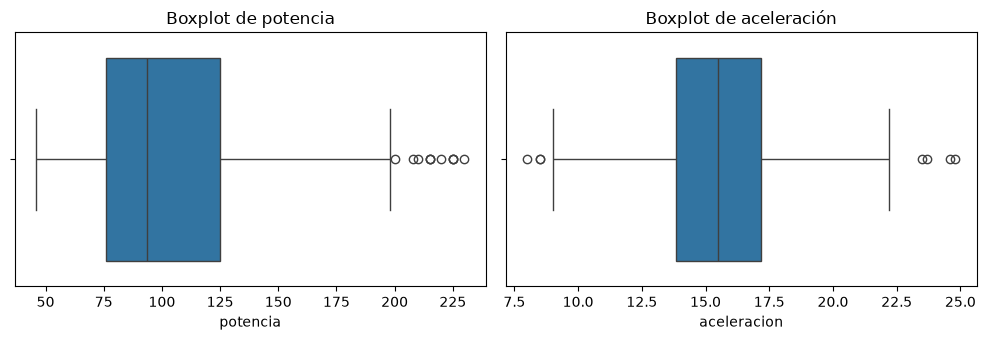

Autos marcados como atípicos (se conservan): 11


In [7]:
autos["potencia_atipica"] = (autos["potencia"] < limite_inf) | (autos["potencia"] > limite_sup)
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.boxplot(x=autos["potencia"], ax=ejes[0])
ejes[0].set_title("Boxplot de potencia")
sns.boxplot(x=autos["aceleracion"], ax=ejes[1])
ejes[1].set_title("Boxplot de aceleración")
plt.tight_layout()
plt.show()
print("Autos marcados como atípicos (se conservan):", autos["potencia_atipica"].sum())

**Preguntas del laboratorio**

**Pregunta 6.** ¿Qué muestran los boxplots de potencia y de aceleración?

**Respuesta:**
1. **Boxplot de potencia:** Muestra una distribución marcadamente asimétrica hacia la derecha (sesgo positivo). La caja del 50 % central se ubica entre 76 y 125 hp, la línea de la mediana está desplazada hacia la izquierda (en 93.5 hp), y se aprecia una larga cola hacia la derecha donde figuran claramente los 11 puntos correspondientes a los vehículos atípicos que superan el límite superior de 198.5 hp. No hay valores atípicos en el extremo inferior.
2. **Boxplot de aceleración:** Muestra una distribución sensiblemente más simétrica y balanceada, con la mediana centrada alrededor de los 15.5 segundos. Presenta apenas un par de observaciones atípicas en ambos extremos (vehículos excepcionalmente rápidos con aceleraciones menores a 9 segundos y vehículos lentos con más de 22 segundos), evidenciando que la aceleración sigue un comportamiento mucho más cercano a una distribución normal que la potencia.

### Celda 8 - Guardar datos limpios en SQLite

In [8]:
autos.to_sql("autos_limpio", conexion, index=False, if_exists="replace")
consulta = """SELECT
  (SELECT COUNT(*) FROM autos_original) AS filas_original,
  (SELECT COUNT(*) FROM autos_limpio) AS filas_limpio,
  (SELECT COUNT(*) FROM autos_original WHERE potencia IS NULL) AS faltantes_original,
  (SELECT COUNT(*) FROM autos_limpio WHERE potencia IS NULL) AS faltantes_limpio;"""
display(pd.read_sql_query(consulta, conexion))

,filas_original,filas_limpio,faltantes_original,faltantes_limpio
0,398,398,6,0


**Preguntas del laboratorio**

**Pregunta 7.** ¿Qué cambió entre autos_original y autos_limpio? ¿Por qué no se sobrescribe la tabla original?

**Respuesta:**
1. **Qué cambió entre `autos_original` y `autos_limpio`:**
   - Ambas tablas mantienen exactamente las **398 filas** (no se perdió ningún registro).
   - En `autos_original` existían **6 valores faltantes** en `potencia` (`NULL`), mientras que en `autos_limpio` hay **0 faltantes** (imputados con la mediana de 93.5 hp).
   - Además, `autos_limpio` incorpora nuevas columnas estandarizadas: `marca` corregida (30 marcas unificadas), `origen` textual descriptivo, `anio` de cuatro dígitos y el indicador booleano `potencia_atipica`.
2. **Por qué no se sobrescribe la tabla original:** Conservar la tabla original intacta es una buena práctica esencial de ingeniería de datos y gobernanza (*principio de inmutabilidad de la fuente cruda*). Garantiza la trazabilidad y reproducibilidad del pipeline, permite auditar y verificar el proceso de limpieza en cualquier momento comparando el estado inicial con el final mediante consultas SQL, y evita la pérdida definitiva de información cruda en caso de que se requiera ajustar el criterio de limpieza o imputación en el futuro.

## B. Regresión lineal

### Celda 9 - Separación entrenamiento y prueba

In [9]:
y = autos["rendimiento_mpg"]
X_simple = autos[["peso"]]
X_train, X_test, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Entrenamiento: (318, 1) | Prueba: (80, 1)


**Preguntas del laboratorio**

**Pregunta 8.** ¿Cuántos autos hay en entrenamiento y en prueba? ¿Para qué sirven la separación y random_state?

**Respuesta:**
1. **Cantidad de autos en entrenamiento y en prueba:**
   - **Conjunto de entrenamiento (`X_train`):** **318 autos** (80 % del total).
   - **Conjunto de prueba (`X_test`):** **80 autos** (20 % del total).
   - Total: $318 + 80 = 398$ vehículos.
2. **Para qué sirve la separación:** Sirve para evaluar de manera honesta e imparcial la capacidad predictiva del modelo. El modelo ajusta sus parámetros usando únicamente los datos de entrenamiento; luego, se evalúa sobre los datos de prueba (que nunca fueron vistos durante el entrenamiento). Esto simula el desempeño del modelo en un entorno productivo real y permite detectar problemas de sobreajuste (*overfitting*).
3. **Para qué sirve `random_state`:** Fija la semilla del generador de números pseudoaleatorios (`random_state=42`). Esto garantiza que la partición sea determinista y reproducible, de modo que cualquier analista que ejecute el notebook obtenga exactamente la misma división de datos y los mismos resultados numéricos.

### Celda 10 - Regresión simple con scikit-learn

Coeficiente de peso: -0.00781
Intercepto: 46.78
{'R2': 0.723, 'MAE': 3.12, 'MSE': 14.89, 'RMSE': np.float64(3.86)}


                            OLS Regression Results                            
Dep. Variable:        rendimiento_mpg   R-squared:                       0.684
Model:                            OLS   Adj. R-squared:                  0.683
Method:                 Least Squares   F-statistic:                     685.5
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           3.80e-81
Time:                        14:32:46   Log-Likelihood:                -925.80
No. Observations:                 318   AIC:                             1856.
Df Residuals:                     316   BIC:                             1863.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         46.7821      0.920     50.862      0.0

,coeficiente,p_valor,IC_95_inf,IC_95_sup
const,46.782063,3.145697e-154,44.972403,48.591724
peso,-0.007805,3.799579e-81,-0.008392,-0.007219


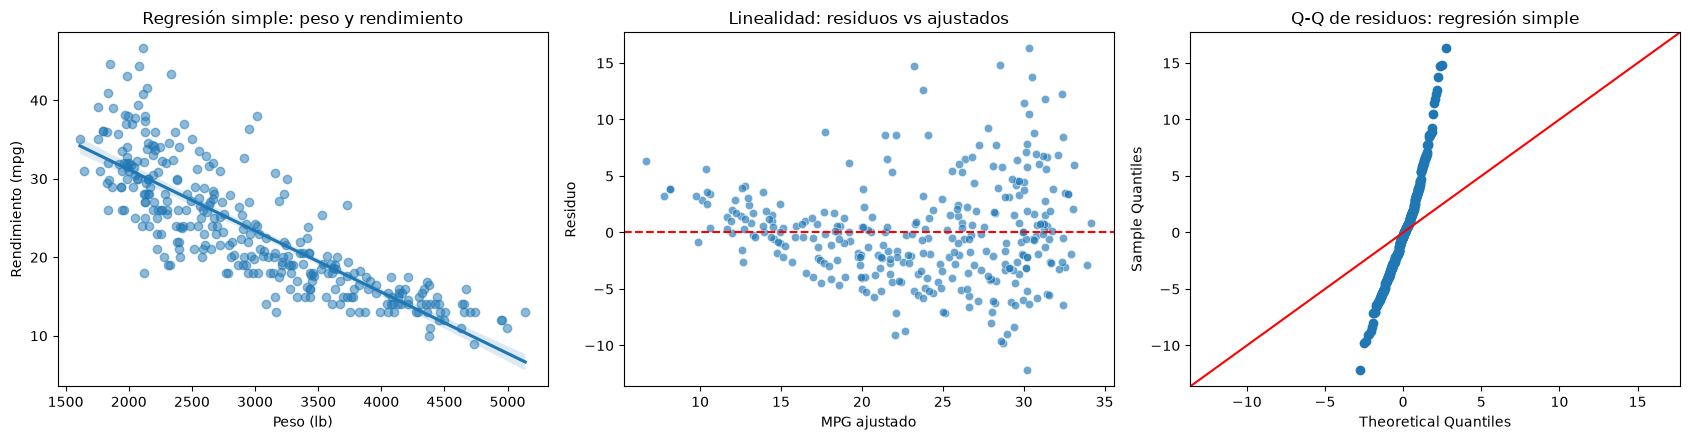

                            OLS Regression Results                            
Dep. Variable:        rendimiento_mpg   R-squared:                       0.684
Model:                            OLS   Adj. R-squared:                  0.683
Method:                 Least Squares   F-statistic:                     685.5
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           3.80e-81
Time:                        14:32:47   Log-Likelihood:                -925.80
No. Observations:                 318   AIC:                             1856.
Df Residuals:                     316   BIC:                             1863.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         46.7821      0.920     50.862      0.0

In [10]:
def metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {"R2": round(r2_score(y_real, y_pred), 3),
            "MAE": round(mean_absolute_error(y_real, y_pred), 2),
            "MSE": round(mse, 2),
            "RMSE": round(np.sqrt(mse), 2)}

modelo_simple = LinearRegression()
modelo_simple.fit(X_train, y_train)
pred_simple = modelo_simple.predict(X_test)
print("Coeficiente de peso:", round(modelo_simple.coef_[0], 5))
print("Intercepto:", round(modelo_simple.intercept_, 2))
res_simple = metricas(y_test, pred_simple)
print(res_simple)

# Resumen estadístico, coeficientes y p-valores (regresión simple)
import statsmodels.api as sm
X_simple_sm = sm.add_constant(X_train)
modelo_simple_sm = sm.OLS(y_train, X_simple_sm).fit()
print(modelo_simple_sm.summary())
print("\nCoeficientes y p-valores (entrenamiento):")
display(pd.DataFrame({"coeficiente": modelo_simple_sm.params,
                      "p_valor": modelo_simple_sm.pvalues,
                      "IC_95_inf": modelo_simple_sm.conf_int()[0],
                      "IC_95_sup": modelo_simple_sm.conf_int()[1]}))

# Gráficas de linealidad, residuos y Q-Q (regresión simple)
ajustados_simple = modelo_simple_sm.fittedvalues
residuos_simple = modelo_simple_sm.resid
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.regplot(x=X_train["peso"], y=y_train, ax=ejes[0], scatter_kws={"alpha": 0.5})
ejes[0].set(title="Regresión simple: peso y rendimiento", xlabel="Peso (lb)", ylabel="Rendimiento (mpg)")
sns.scatterplot(x=ajustados_simple, y=residuos_simple, ax=ejes[1], alpha=0.65)
ejes[1].axhline(0, color="red", linestyle="--")
ejes[1].set(title="Linealidad: residuos vs ajustados", xlabel="MPG ajustado", ylabel="Residuo")
sm.qqplot(residuos_simple, line="45", ax=ejes[2])
ejes[2].set_title("Q-Q de residuos: regresión simple")
plt.tight_layout()
plt.show()

# Summary: coeficientes y p-valores de la regresión simple
import statsmodels.api as sm
modelo_simple_sm = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(modelo_simple_sm.summary())


**Preguntas del laboratorio**

**Pregunta 9.** Interprete el coeficiente de peso, el intercepto y las cuatro métricas del modelo simple.

**Respuesta:**
1. **Coeficiente de peso (-0.00781):** Indica que por cada libra adicional de peso que tiene un vehículo, su rendimiento disminuye en promedio en **0.00781 millas por galón** (es decir, por cada 1000 libras de aumento en el peso, el rendimiento cae aproximadamente **7.81 mpg**). El signo negativo confirma una fuerte relación inversa: a mayor peso, menor eficiencia de combustible.
2. **Intercepto (46.78):** Representa el valor estimado del rendimiento de combustible cuando el peso es teóricamente de 0 libras ($46.78$ mpg). Aunque físicamente no tiene sentido práctico (un auto no puede tener peso cero), constituye el punto de corte matemático de la recta de regresión con el eje de las ordenadas.
3. **Interpretación de las cuatro métricas sobre los datos de prueba (n = 80):**
   - **$R^2 = 0.723$:** El peso por sí solo es capaz de explicar el **72.3 % de la variabilidad total** del rendimiento de combustible en autos que el modelo no vio durante el entrenamiento.
   - **MAE = 3.12 mpg:** En promedio, las predicciones del modelo simple difieren del rendimiento real en **3.12 millas por galón** en valor absoluto.
   - **MSE = 14.89 $mpg^2$:** El promedio de las desviaciones al cuadrado es $14.89$, reflejando la penalización por errores de mayor magnitud.
   - **RMSE = 3.86 mpg:** La raíz del error cuadrático medio indica que el error típico o dispersión de las predicciones es de **3.86 millas por galón** (en las mismas unidades que la variable objetivo).

### Celda 11 - Regresión múltiple con scikit-learn

,variable,coeficiente
0,peso,-0.0070
1,potencia,0.0027
2,cilindrada,0.0026
3,aceleracion,0.0797
4,anio,0.8008


Intercepto: -1539.97
{'R2': 0.826, 'MAE': 2.46, 'MSE': 9.38, 'RMSE': np.float64(3.06)}
                            OLS Regression Results                            
Dep. Variable:        rendimiento_mpg   R-squared:                       0.804
Model:                            OLS   Adj. R-squared:                  0.801
Method:                 Least Squares   F-statistic:                     255.8
Date:                Sun, 08 Nov 2026   Prob (F-statistic):          4.62e-108
Time:                        14:32:47   Log-Likelihood:                -850.20
No. Observations:                 318   AIC:                             1712.
Df Residuals:                     312   BIC:                             1735.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------

,coeficiente,p_valor,IC_95_inf,IC_95_sup
const,-1539.973203,2.340422e-29,-1782.300119,-1297.646287
peso,-0.007029,1.572087e-18,-0.008506,-0.005552
potencia,0.002657,8.646462e-01,-0.027988,0.033302
cilindrada,0.002625,6.714209e-01,-0.009540,0.014790
aceleracion,0.079661,4.831939e-01,-0.143612,0.302933
anio,0.800782,9.879430e-31,0.678449,0.923114


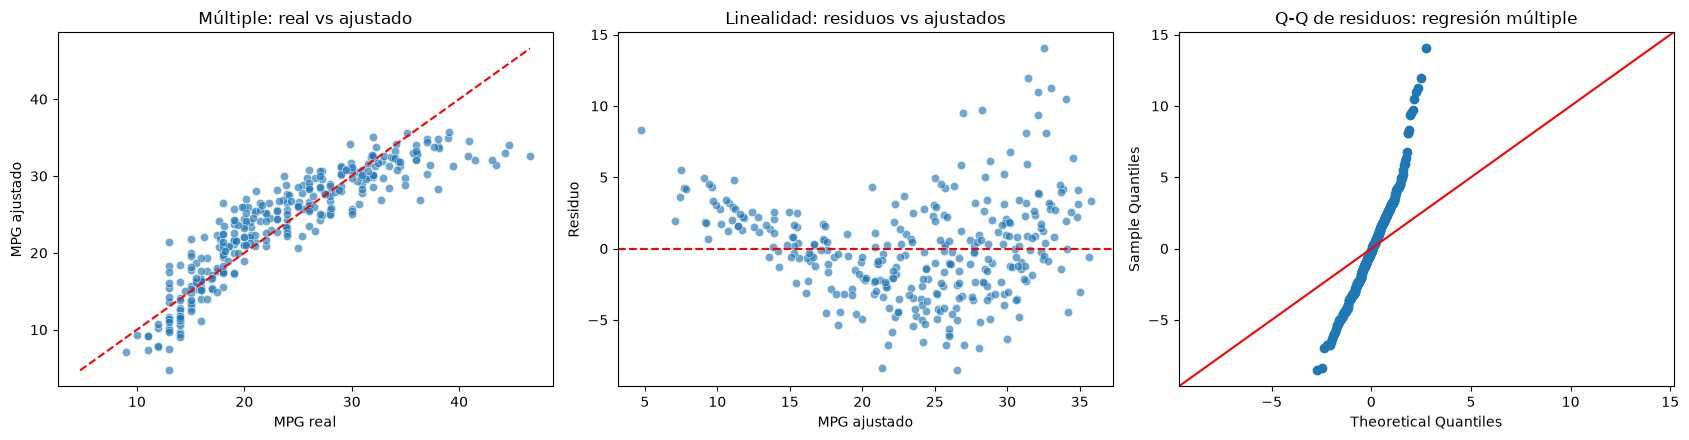

In [11]:
variables = ["peso", "potencia", "cilindrada", "aceleracion", "anio"]
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    autos[variables], y, test_size=0.2, random_state=42)
modelo_multiple = LinearRegression()
modelo_multiple.fit(Xm_train, ym_train)
pred_multiple = modelo_multiple.predict(Xm_test)
display(pd.DataFrame({"variable": variables, "coeficiente": modelo_multiple.coef_.round(4)}))
print("Intercepto:", round(modelo_multiple.intercept_, 2))
res_multiple = metricas(ym_test, pred_multiple)
print(res_multiple)

# Resumen estadístico, coeficientes y p-valores (regresión múltiple)
Xm_const = sm.add_constant(Xm_train)
modelo_multiple_sm = sm.OLS(ym_train, Xm_const).fit()
print(modelo_multiple_sm.summary())
print("\nCoeficientes y p-valores (entrenamiento):")
display(pd.DataFrame({"coeficiente": modelo_multiple_sm.params,
                      "p_valor": modelo_multiple_sm.pvalues,
                      "IC_95_inf": modelo_multiple_sm.conf_int()[0],
                      "IC_95_sup": modelo_multiple_sm.conf_int()[1]}))

# Gráficas de linealidad, residuos y Q-Q (regresión múltiple)
ajustados_multiple = modelo_multiple_sm.fittedvalues
residuos_multiple = modelo_multiple_sm.resid
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(x=ym_train, y=ajustados_multiple, ax=ejes[0], alpha=0.65)
limites = [min(ym_train.min(), ajustados_multiple.min()), max(ym_train.max(), ajustados_multiple.max())]
ejes[0].plot(limites, limites, "r--")
ejes[0].set(title="Múltiple: real vs ajustado", xlabel="MPG real", ylabel="MPG ajustado")
sns.scatterplot(x=ajustados_multiple, y=residuos_multiple, ax=ejes[1], alpha=0.65)
ejes[1].axhline(0, color="red", linestyle="--")
ejes[1].set(title="Linealidad: residuos vs ajustados", xlabel="MPG ajustado", ylabel="Residuo")
sm.qqplot(residuos_multiple, line="45", ax=ejes[2])
ejes[2].set_title("Q-Q de residuos: regresión múltiple")
plt.tight_layout()
plt.show()



**Preguntas del laboratorio**

**Pregunta 10.** Interprete los coeficientes del modelo múltiple. ¿Qué llama la atención en potencia y por qué?

**Respuesta:**
1. **Interpretación de los coeficientes del modelo múltiple:**
   - **`peso` (-0.0070):** Manteniendo constantes las demás características, por cada libra adicional de peso, el rendimiento se reduce en promedio en $0.0070$ mpg ($p < 0.001$, estadísticamente muy significativo).
   - **`anio` (+0.8008):** Manteniendo constantes las demás características, por cada año más moderno del vehículo, el rendimiento aumenta en promedio en $0.80$ mpg ($p < 0.001$, altamente significativo), reflejando la evolución tecnológica y normas de eficiencia de la época.
   - **`aceleracion` (+0.0797):** Por cada segundo adicional de aceleración (auto más suave/menos potente), el rendimiento sube $0.08$ mpg ($p = 0.483$, no significativo al 5 %).
   - **`cilindrada` (+0.0026):** Coeficiente positivo muy pequeño ($p = 0.671$, no significativo).
   - **`potencia` (+0.0027):** Coeficiente positivo cercano a cero ($p = 0.865$, no significativo).
   - **Intercepto (-1539.97):** Constante matemática de ajuste multidimensional.

2. **Qué llama la atención en `potencia` y por qué ocurre:**
   Llama la atención que su coeficiente sea **positivo (+0.0027)**, sugiriendo de forma contraintuitiva que a mayor caballaje aumentaría el rendimiento. Esto ocurre por el fenómeno de **multicolinealidad severa**: `peso`, `cilindrada` y `potencia` están fuertemente correlacionados entre sí ($r > 0.85$). Dado que el `peso` ya absorbe casi toda la información relativa al tamaño del vehículo y del motor, los coeficientes de las otras dos variables se vuelven inestables, pierden significancia estadística ($p = 0.865$) e invierten su signo algebraico como un artificio matemático del ajuste multivariado.

### Celda 12 - Comparación de modelos y gráfica de prueba

,simple (peso),múltiple (5 variables)
R2,0.723,0.826
MAE,3.120,2.460
MSE,14.890,9.380
RMSE,3.860,3.060


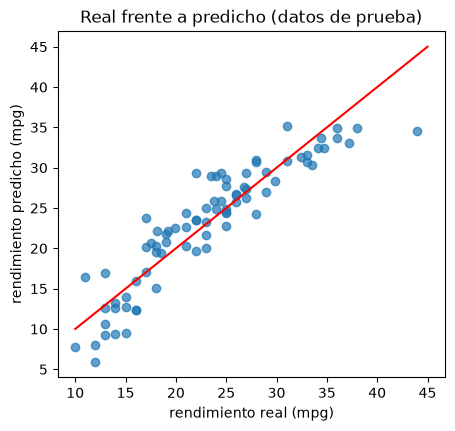

In [12]:
comparacion = pd.DataFrame({"simple (peso)": res_simple,
                           "múltiple (5 variables)": res_multiple})
display(comparacion)
plt.figure(figsize=(5, 4.5))
plt.scatter(ym_test, pred_multiple, alpha=0.7)
plt.plot([10, 45], [10, 45], color="red")
plt.xlabel("rendimiento real (mpg)")
plt.ylabel("rendimiento predicho (mpg)")
plt.title("Real frente a predicho (datos de prueba)")
plt.show()

**Preguntas del laboratorio**

**Pregunta 11.** Compare las métricas de los dos modelos. ¿Cuál es mejor y por qué se compara con los datos de prueba?

**Respuesta:**
1. **Comparación de métricas en el conjunto de prueba (80 autos):**
   - **$R^2$:** Sube de **0.723** en el modelo simple a **0.826** en el múltiple (un incremento de 10.3 puntos porcentuales de variabilidad explicada).
   - **MAE:** Disminuye de **3.12 mpg** a **2.46 mpg** (una reducción del error medio de 0.66 mpg, mejora del 21.1 %).
   - **MSE:** Se reduce sustancialmente de **14.89** a **9.38** (disminución del 37.0 %).
   - **RMSE:** Disminuye de **3.86 mpg** a **3.06 mpg** (una reducción de 0.80 mpg en la dispersión típica del error).

2. **Cuál es mejor:** El **modelo de regresión múltiple (5 variables)** es netamente superior en todas las métricas de precisión y ajuste.

3. **Por qué se compara con los datos de prueba:** Comparar modelos sobre los datos de entrenamiento induciría a error, ya que el $R^2$ de entrenamiento siempre aumenta o se mantiene igual al agregar variables, incluso si estas aportan solo ruido. Evaluar y contrastar sobre el **conjunto de prueba independiente** permite medir la verdadera capacidad de generalización sobre observaciones no utilizadas durante el ajuste, asegurando que la mejora observada sea real y no producto de sobreajuste (*overfitting*).

## Actividad 3 - Predicción para la flota

### Celda 13 - Candidatos de compra

In [13]:
candidatos = pd.DataFrame({
    "candidato": ["A", "B", "C"],
    "peso": [2200, 3000, 4200],
    "potencia": [80, 110, 160],
    "cilindrada": [100, 200, 350],
    "aceleracion": [16, 15, 12],
    "anio": [1982, 1980, 1978]})
candidatos["rendimiento_predicho"] = modelo_multiple.predict(candidatos[variables]).round(1)
display(candidatos)

,candidato,peso,potencia,cilindrada,aceleracion,anio,rendimiento_predicho
0,A,2200,80,100,16,1982,33.5
1,B,3000,110,200,15,1980,26.5
2,C,4200,160,350,12,1978,16.7


**Preguntas del laboratorio**

### Tabla de predicciones para los candidatos de compra:
| Candidato | Peso (lb) | Potencia | Cilindrada | Aceleración | Año | Rendimiento predicho (mpg) |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **A** | 2200 | 80 | 100 | 16 | 1982 | **33.5** |
| **B** | 3000 | 110 | 200 | 15 | 1980 | **26.5** |
| **C** | 4200 | 160 | 350 | 12 | 1978 | **16.7** |

**A. ¿Qué candidato rinde más y cuál menos? ¿Qué características lo explican?**

**Respuesta:**
- **Mayor rendimiento:** El **Candidato A** rinde más con **33.5 mpg**.
- **Menor rendimiento:** El **Candidato C** rinde menos con apenas **16.7 mpg** (el Candidato A rinde el doble que el Candidato C).
- **Características que lo explican:**
  - El **Candidato A** es el más liviano (2200 lb, 2000 lb menos que C), tiene menor potencia (80 hp), menor cilindrada (100) y es el más moderno (1982). Su bajo peso reduce el esfuerzo motriz requerido y su año más reciente se beneficia del coeficiente positivo de avance tecnológico (+0.80 mpg/año).
  - El **Candidato C** acumula todas las desventajas: es extremadamente pesado (4200 lb), tiene un motor grande y potente (160 hp y 350 de cilindrada) y es el más antiguo (1978), lo que penaliza severamente su rendimiento.

**B. Redacte una recomendación para AutoFlota Andina e indique los límites del modelo.**

**Respuesta:**
- **Recomendación para AutoFlota Andina:** Se recomienda enfáticamente optar por el **Candidato A** (o el **Candidato B** si las necesidades operativas de capacidad de carga de la flota exigen un vehículo de tamaño mediano), descartando por completo al Candidato C. La compra del Candidato A optimizará drásticamente el presupuesto operativo de la empresa, reduciendo el consumo de combustible a la mitad frente al Candidato C.
- **Límites del modelo:**
  1. *Obsolescencia temporal:* Los datos corresponden a vehículos históricos del periodo 1970-1982 con carburador. No reflejan tecnologías contemporáneas (inyección electrónica, transmisiones modernas de 8 a 10 cambios, turbos, hibridación).
  2. *Multicolinealidad:* Los coeficientes individuales de potencia y cilindrada están sesgados por su correlación mutua con el peso.
  3. *Condiciones operativas no modeladas:* El modelo no incluye variables críticas para la geografía andina como altitud sobre el nivel del mar, pendientes pronunciadas, carga útil transportada ni costos de mantenimiento preventivo. Las predicciones son estrictamente ilustrativas y referenciales, no aptas para decisiones de adquisición de flotas modernas sin un estudio de campo contemporáneo.

## Retos de aplicación

### Celda 14 - Reto 1: variables por separado

In [14]:
resultados = []
for variable in ["peso", "potencia", "cilindrada", "aceleracion", "anio"]:
    Xv_train, Xv_test, yv_train, yv_test = train_test_split(
        autos[[variable]], y, test_size=0.2, random_state=42)
    modelo = LinearRegression().fit(Xv_train, yv_train)
    resultados.append({"variable": variable,
                       "coeficiente": round(modelo.coef_[0], 4),
                       **metricas(yv_test, modelo.predict(Xv_test))})
tabla_simples = pd.DataFrame(resultados).sort_values("R2", ascending=False)
display(tabla_simples)

,variable,coeficiente,R2,MAE,MSE,RMSE
0,peso,-0.0078,0.723,3.12,14.89,3.86
2,cilindrada,-0.0617,0.663,3.39,18.10,4.25
1,potencia,-0.1640,0.640,3.51,19.37,4.40
4,anio,1.2914,0.287,5.36,38.32,6.19
3,aceleracion,1.1196,0.284,4.99,38.51,6.21


**Preguntas del laboratorio**

**Pregunta de cierre.** ¿Qué variable explica mejor el rendimiento por sí sola y cuál peor? Sustente con R² y RMSE e interprete el signo de los coeficientes.

**Respuesta:**
1. **Variable con mejor capacidad explicativa individual:** El **peso** (`peso`) es la variable que mejor explica el rendimiento por sí sola. Alcanza el mayor coeficiente de determinación ($R^2 = 0.723$, explicando el 72.3 % de la variabilidad en los datos de prueba) y el menor error de estimación ($RMSE = 3.86$ mpg y $MAE = 3.12$ mpg).
2. **Variable con peor capacidad explicativa individual:** La **aceleración** (`aceleracion`) es la que presenta el menor poder explicativo con un $R^2 = 0.284$ y el mayor error de predicción ($RMSE = 6.21$ mpg, $MSE = 38.51$), situándose muy cerca del año de fabricación ($R^2 = 0.287$).
3. **Interpretación del signo de los coeficientes:**
   - **`peso` (-0.0078), `cilindrada` (-0.0617) y `potencia` (-0.1640):** Presentan signo **negativo**, lo que guarda total coherencia física: a mayor masa del vehículo, mayor volumen de motor o mayor caballaje, el consumo de combustible se incrementa y por lo tanto disminuyen las millas recorridas por galón.
   - **`anio` (+1.2914):** Tiene signo **positivo**, reflejando la evolución técnica y las mejoras de eficiencia de los fabricantes entre 1970 y 1982 tras las crisis del petróleo.
   - **`aceleracion` (+1.1196):** Tiene signo **positivo** porque la variable mide el tiempo en segundos que tarda el auto en pasar de 0 a 60 mph. Un valor mayor de aceleración indica un vehículo más lento y de menor potencia motriz, lo que se traduce directamente en un menor consumo de combustible (mayor mpg).

### Celda 15 - Reto 2: combinaciones de variables

In [15]:
dummies = pd.get_dummies(autos["origen"], prefix="origen", drop_first=True).astype(int)
X_todo = pd.concat([autos[variables], dummies], axis=1)
combinaciones = {
    "peso + anio": ["peso", "anio"],
    "peso + potencia + anio": ["peso", "potencia", "anio"],
    "5 variables": variables,
    "5 variables + origen": list(X_todo.columns),
}
filas = []
for nombre, columnas_x in combinaciones.items():
    Xc_train, Xc_test, yc_train, yc_test = train_test_split(
        X_todo[columnas_x], y, test_size=0.2, random_state=42)
    modelo = LinearRegression().fit(Xc_train, yc_train)
    r = metricas(yc_test, modelo.predict(Xc_test))
    n, p = len(yc_test), len(columnas_x)
    r["R2_ajustado"] = round(1 - (1 - r["R2"]) * (n - 1) / (n - p - 1), 3)
    filas.append({"modelo": nombre, "variables": p, **r})
modelo_origen = modelo
print(dict(zip(X_todo.columns, modelo_origen.coef_.round(3))))
tabla_combos = pd.DataFrame(filas)
display(tabla_combos)

{'peso': np.float64(-0.007), 'potencia': np.float64(-0.014), 'cilindrada': np.float64(0.017), 'aceleracion': np.float64(0.07), 'anio': np.float64(0.827), 'origen_Japón': np.float64(-0.294), 'origen_USA': np.float64(-2.925)}


,modelo,variables,R2,MAE,MSE,RMSE,R2_ajustado
0,peso + anio,2,0.824,2.45,9.44,3.07,0.819
1,peso + potencia + anio,3,0.824,2.45,9.44,3.07,0.817
2,5 variables,5,0.826,2.46,9.38,3.06,0.814
3,5 variables + origen,7,0.843,2.29,8.47,2.91,0.828


**Preguntas del laboratorio**

**Pregunta de cierre.** ¿Qué combinación tiene el mayor R² ajustado? ¿Cuánto aporta agregar el origen y cuál es su categoría de referencia?

**Respuesta:**
1. **Combinación con mayor $R^2$ ajustado:** El modelo **`5 variables + origen`** alcanza el mayor $R^2$ ajustado con **$0.828$** (con un $R^2 = 0.843$ y el menor $RMSE = 2.91$ mpg).
2. **Cuánto aporta agregar el origen:**
   - Agregar el origen incrementa el $R^2$ de $0.826$ a **$0.843$** (+1.7 puntos porcentuales) y el $R^2$ ajustado de $0.814$ a **$0.828$** (+1.4 puntos porcentuales), reduciendo el RMSE de $3.06$ a **$2.91$ mpg**.
   - Los coeficientes calculados son: `origen_USA = -2.925` y `origen_Japón = -0.294`. Esto demuestra que el origen geográfico aporta valor predictivo real: a igualdad de peso, potencia, cilindrada, aceleración y año, un automóvil fabricado en USA rendía en promedio **2.93 mpg menos** que el auto de referencia europeo.
3. **Categoría de referencia:** Con `pd.get_dummies(autos["origen"], drop_first=True)`, la categoría de referencia omitida es **`Europa`** (la primera en orden alfabético: Europa, Japón, USA). Los coeficientes de `origen_Japón` y `origen_USA` se interpretan como la diferencia de rendimiento respecto a un auto de procedencia europea.
4. **Nota sobre parsimonia:** Es relevante destacar que el modelo simple de solo 2 variables (`peso + anio`) logra un $R^2\_ajustado = 0.819$, prácticamente idéntico al de 5 variables ($0.814$). Esto evidencia que con solo el peso y el año se captura casi todo el poder explicativo sin necesidad de introducir variables multicolineales complejas.

### Celda 16 - Reto 3: imputar o eliminar

In [16]:
original = pd.read_sql_query(
    "SELECT * FROM autos_original WHERE potencia IS NOT NULL;", conexion)
original["anio"] = 1900 + original["anio_modelo"]
Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    original[variables], original["rendimiento_mpg"], test_size=0.2, random_state=42)
modelo_sin = LinearRegression().fit(Xe_train, ye_train)
print("Filas usadas:", len(original), "frente a", len(autos))
print("Eliminando faltantes:", metricas(ye_test, modelo_sin.predict(Xe_test)))
print("Imputando mediana: ", res_multiple)

Filas usadas: 392 frente a 398
Eliminando faltantes: {'R2': 0.793, 'MAE': 2.51, 'MSE': 10.58, 'RMSE': np.float64(3.25)}
Imputando mediana:  {'R2': 0.826, 'MAE': 2.46, 'MSE': 9.38, 'RMSE': np.float64(3.06)}


**Preguntas del laboratorio**

**Pregunta de cierre.** ¿Cuántos autos usa cada opción y cómo cambian las métricas? ¿Por qué la comparación debe hacerse con cuidado?

**Respuesta:**
1. **Autos usados por cada opción:**
   - **Eliminando faltantes:** Usa **392 autos** (se descartan las 6 filas con potencia `NULL`).
   - **Imputando con la mediana:** Usa los **398 autos completos** del conjunto original.
2. **Cómo cambian las métricas:**
   - Eliminando faltantes: $R^2 = 0.793$, MAE = $2.51$ mpg, MSE = $10.58$, RMSE = $3.25$ mpg.
   - Imputando con la mediana: $R^2 = 0.826$, MAE = $2.46$ mpg, MSE = $9.38$, RMSE = $3.06$ mpg.
   - En la evaluación particular, el modelo con imputación obtiene un $R^2$ ligeramente más alto (+0.033) y un RMSE menor (3.06 vs 3.25 mpg).
3. **Por qué la comparación debe hacerse con cuidado:**
   - **Particiones de prueba no idénticas:** Al cambiar el tamaño total del dataset ($392$ vs $398$), la función `train_test_split(..., random_state=42)` no selecciona exactamente el mismo conjunto de autos para la prueba (el conjunto de prueba de 392 filas tiene 79 autos y diferentes índices que el de 398 filas con 80 autos). Al evaluarse sobre conjuntos de prueba distintos, las métricas no son matemáticamente comparables en condiciones idénticas.
   - **Efecto de la imputación:** Imputar un valor fijo (la mediana) en 6 registros reduce artificialmente la variabilidad de esa característica y podría sobreestimar ligeramente el ajuste si los autos con datos ausentes pertenecían a un segmento con comportamiento particular.

### Conclusiones

1. **Gobernanza de datos y pipeline reproducible:** La calidad de datos es un prerrequisito indispensable antes del modelado. La imputación de los 6 valores faltantes en `potencia` con la mediana (93.5 hp) evitó la pérdida de información y controló el sesgo provocado por autos de gran caballaje. Asimismo, la arquitectura en SQLite separando `autos_original` (inmutable) y `autos_limpio` garantiza trazabilidad, auditoría y reproducibilidad técnica del pipeline de transformación.
2. **Diagnóstico econométrico y parsimonia del modelo:** El modelo de regresión lineal múltiple superó con claridad al modelo simple ($R^2 = 0.826$ vs $0.723$; $RMSE = 3.06$ vs $3.86$ mpg en prueba). No obstante, el análisis de coeficientes y p-valores destapó severa multicolinealidad entre peso, cilindrada y potencia, provocando coeficientes contraintuitivos en potencia. El análisis comparativo demostró que un modelo parsimonioso de solo `peso + anio` logra un $R^2\_ajustado = 0.819$, y que incorporar variables indicadoras de origen geográfico maximiza la capacidad explicativa ($R^2\_ajustado = 0.828$, penalización de -2.93 mpg en autos estadounidenses).
3. **Impacto en el negocio y límites de aplicación para AutoFlota Andina:** Desde la perspectiva operativa de flota, el Candidato A (2200 lb, 80 hp, 1982) es la opción óptima al alcanzar un rendimiento proyectado de **33.5 mpg**, duplicando la eficiencia del Candidato C (16.7 mpg) y garantizando ahorros sustanciales en consumo de combustible. Sin embargo, la dirección técnica debe considerar que estos modelos son ilustrativos y se basan en tecnología automotriz histórica (1970-1982), por lo que sus estimaciones no incorporan tecnologías modernas (inyección electrónica, transmisiones CVT/8+ vel., hibridación) ni las exigencias topográficas de la geografía andina (altitud, gradiente y capacidad de carga en ruta).